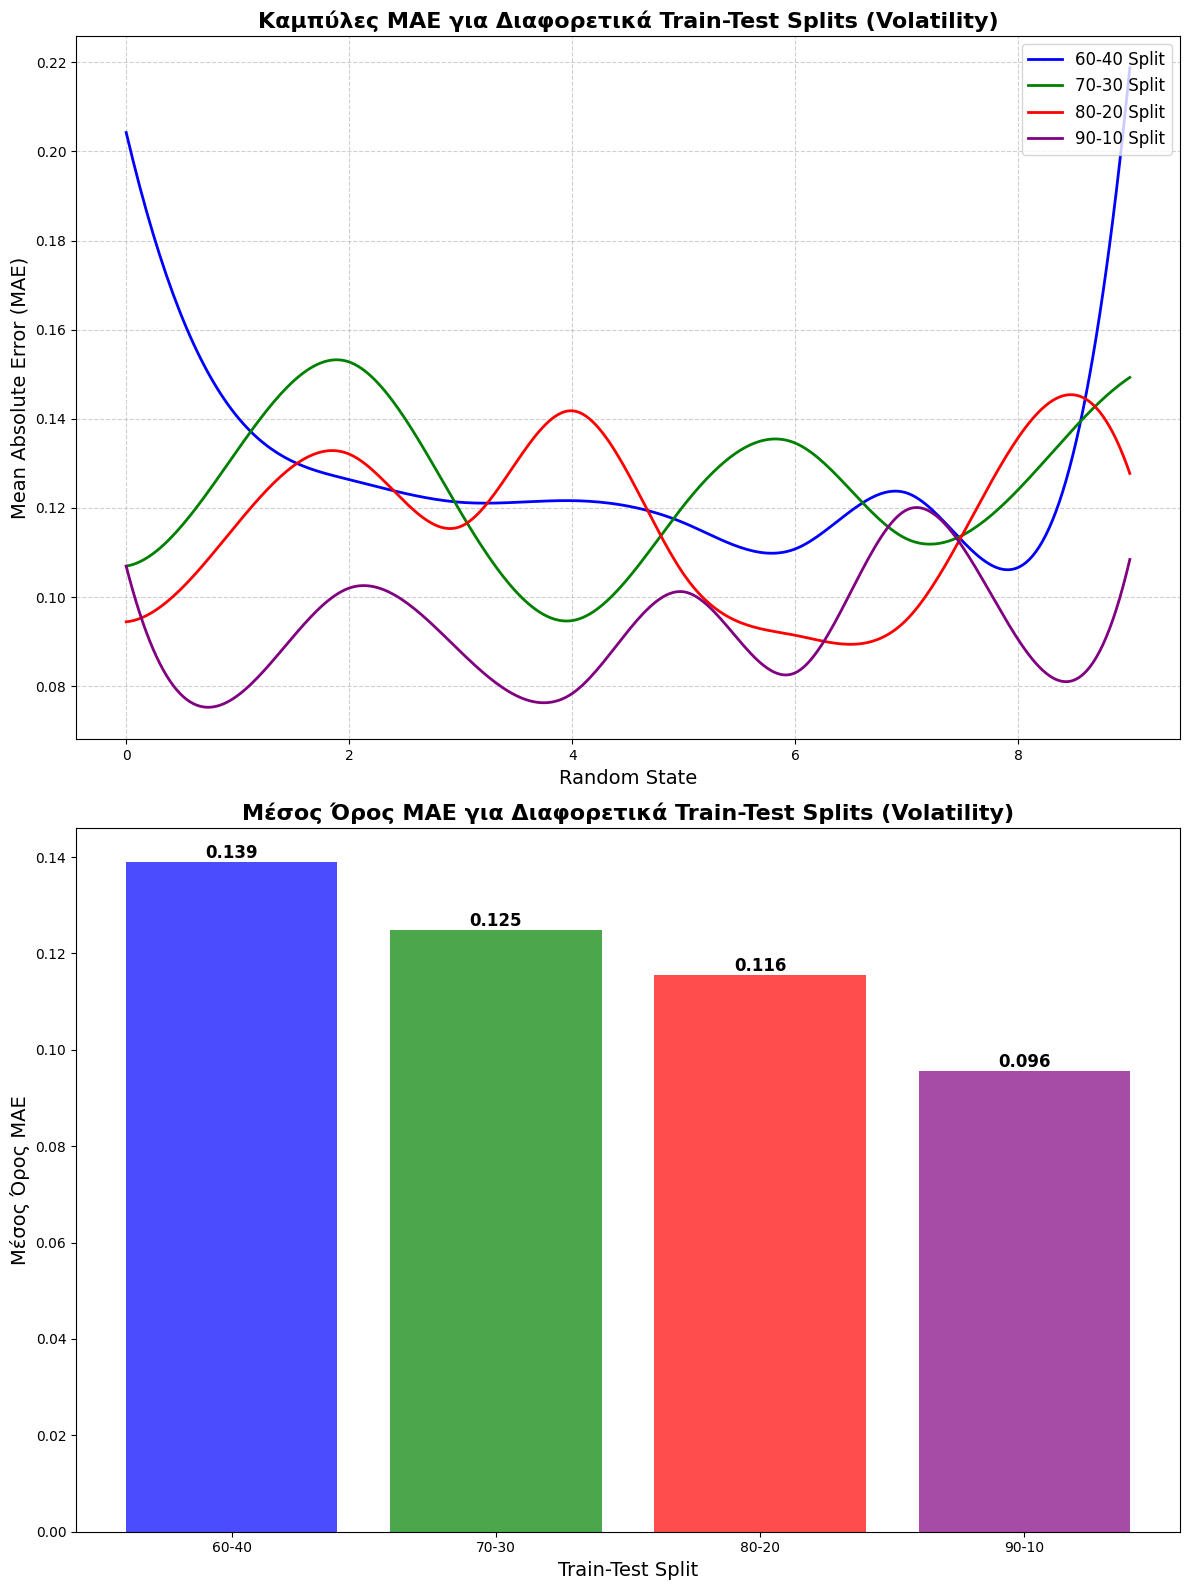

In [1]:

import matplotlib.pyplot as plt
import numpy as np
from scipy.interpolate import make_interp_spline

# Δεδομένα για τα splits
random_states = np.array(list(range(10)))

mae_60_40 = np.array([
    0.20422494687490134, 0.140347233907285, 0.12634804233473074,
    0.12125897429862444, 0.12162862660277304, 0.11665890684882738,
    0.11080314720748574, 0.1233522442155232, 0.10664838328380158,
    0.21874788535541742
])
mae_70_30 = np.array([
    0.10693971899768338, 0.1330503687203721, 0.15274144206703139,
    0.11900642570331721, 0.0947188868495343, 0.12056324309746907,
    0.1345418043945899, 0.11304113744948274, 0.12411888287100956,
    0.14927367987733306
])
mae_80_20 = np.array([
    0.09444131765717739, 0.11654783984294215, 0.13207151944575318,
    0.11584814002613866, 0.14179613967761054, 0.10509730411139187,
    0.09142524273340479, 0.09495869337442141, 0.13581026932951962,
    0.12774410698621075
])
mae_90_10 = np.array([
    0.10691832449718054, 0.0779157540992616, 0.10201618582161726,
    0.08768519990925522, 0.07836659962789418, 0.10117870271064233,
    0.08300422147697574, 0.11957517301947351, 0.09041363899686267,
    0.10843910213568794
])

# Υπολογισμός μέσου όρου για κάθε split
mean_mae = [
    mae_60_40.mean(),
    mae_70_30.mean(),
    mae_80_20.mean(),
    mae_90_10.mean()
]

splits = ["60-40", "70-30", "80-20", "90-10"]

# Δημιουργία λείων καμπυλών με Spline Interpolation
x_smooth = np.linspace(random_states.min(), random_states.max(), 300)

mae_60_40_smooth = make_interp_spline(random_states, mae_60_40)(x_smooth)
mae_70_30_smooth = make_interp_spline(random_states, mae_70_30)(x_smooth)
mae_80_20_smooth = make_interp_spline(random_states, mae_80_20)(x_smooth)
mae_90_10_smooth = make_interp_spline(random_states, mae_90_10)(x_smooth)

# Δημιουργία γραφικής παράστασης
fig, axes = plt.subplots(2, 1, figsize=(12, 16))

# Πρώτο γράφημα: Καμπύλες MAE
axes[0].plot(x_smooth, mae_60_40_smooth, color='blue', label='60-40 Split', linewidth=2)
axes[0].plot(x_smooth, mae_70_30_smooth, color='green', label='70-30 Split', linewidth=2)
axes[0].plot(x_smooth, mae_80_20_smooth, color='red', label='80-20 Split', linewidth=2)
axes[0].plot(x_smooth, mae_90_10_smooth, color='purple', label='90-10 Split', linewidth=2)


axes[0].set_title('Καμπύλες MAE για Διαφορετικά Train-Test Splits (Volatility)', fontsize=16, fontweight='bold')
axes[0].set_xlabel('Random State', fontsize=14)
axes[0].set_ylabel('Mean Absolute Error (MAE)', fontsize=14)
axes[0].grid(True, linestyle='--', alpha=0.6)
axes[0].legend(fontsize=12, loc='upper right')

# Δεύτερο γράφημα: Bar Chart Μέσων Όρων MAE
bars = axes[1].bar(splits, mean_mae, color=['blue', 'green', 'red', 'purple'], alpha=0.7)

axes[1].set_title('Μέσος Όρος MAE για Διαφορετικά Train-Test Splits (Volatility)', fontsize=16, fontweight='bold')
axes[1].set_xlabel('Train-Test Split', fontsize=14)
axes[1].set_ylabel('Μέσος Όρος MAE', fontsize=14)

# Προσθήκη τιμών πάνω από τις μπάρες
for bar, value in zip(bars, mean_mae):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f'{value:.3f}',
        ha='center', va='bottom', fontsize=12, fontweight='bold'
    )

plt.tight_layout()
plt.show()
